<a href="https://colab.research.google.com/github/Salalahmdi/Advanced-Statistics-Transportation/blob/main/Statistics_Midterm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced Statistics
Questions 1–9

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from pathlib import Path
from IPython.display import display

paths = [Path('pavement_transportation_master_dataset(5).csv'), Path('pavement_transportation_master_dataset.csv')]
path = next((p for p in paths if p.exists()), None)
if path is None:
    from google.colab import files
    uploaded = files.upload()
    path = next(Path(name) for name in uploaded if name.lower().endswith('.csv'))
df = pd.read_csv(path)
col = 'freeze_thaw_cycles'
alpha = 0.05
print('Dataset shape:', df.shape)

Dataset shape: (2400, 33)


## 1. Imputation: mean, median and KNN
Validation hides valid values in the same climate proportions as invalid values. KNN uses three neighbors within each climate, with standardized temperature and rainfall.

In [2]:
invalid = df[col] < 0
valid = df.loc[~invalid].copy()
print('Invalid values:', invalid.sum())
print(df.loc[invalid, 'climate_zone'].value_counts())
rng = np.random.default_rng(42)
idx = []
for zone, count in df.loc[invalid, 'climate_zone'].value_counts().items():
    pool = valid.loc[valid['climate_zone'] == zone]
    idx.extend(rng.choice(pool.index, size=count, replace=False))
test = valid.loc[idx].copy()
train = valid.drop(idx)
y = test[col]
pred_mean = np.rint(train[col].mean())
pred_median = train[col].median()
pred_knn = pd.Series(index=test.index, dtype=float)
features = ['mean_temp_C', 'annual_rainfall_mm']
for zone, group in test.groupby('climate_zone'):
    tr = train.loc[train['climate_zone'] == zone]
    scaler = StandardScaler()
    a = scaler.fit_transform(tr[features])
    b = scaler.transform(group[features])
    train_knn = np.column_stack([a, tr[col].to_numpy()])
    test_knn = np.column_stack([b, np.full(len(group), np.nan)])
    imputer = KNNImputer(n_neighbors=3)
    imputer.fit(train_knn)
    pred_knn.loc[group.index] = np.rint(imputer.transform(test_knn)[:, -1])
results = []
for name, pred in [('Mean', pred_mean), ('Median', pred_median), ('KNN', pred_knn)]:
    error = y - pred
    results.append([name, np.abs(error).mean(), np.sqrt((error**2).mean())])
display(pd.DataFrame(results, columns=['Method', 'MAE', 'RMSE']).round(2))
df_corrected = df.copy()
median = valid[col].median()
df_corrected.loc[invalid, col] = median
print('Replacement value:', median)
print('Remaining negative values:', (df_corrected[col] < 0).sum())
print('Number of rows:', len(df_corrected))
df_corrected.to_csv('pavement_corrected_q1.csv', index=False)

Invalid values: 166
climate_zone
Temperate    160
Semi-Arid      6
Name: count, dtype: int64


,Method,MAE,RMSE
0,Mean,10.39,11.75
1,Median,6.30,7.63
2,KNN,6.35,7.83


Replacement value: 15.0
Remaining negative values: 0
Number of rows: 2400


## 2. Central tendency and dispersion
Population variance and standard deviation (ddof=0).

In [11]:
def descriptive(x):
    return pd.Series({'Mean': x.mean(), 'Median': x.median(), 'Mode': x.mode().iloc[0],
                      'Variance': x.var(ddof=0), 'Standard deviation': x.std(ddof=0),
                      'Minimum': x.min(), 'Q1': x.quantile(.25), 'Q3': x.quantile(.75),
                      'Maximum': x.max(), 'Range': x.max()-x.min(),
                      'IQR': x.quantile(.75)-x.quantile(.25)})
before = df[col]
after = df_corrected[col]
display(pd.DataFrame({'Before': descriptive(before), 'After': descriptive(after)}).round(2))

,Before,After
Mean,18.35,19.68
Median,14.00,15.00
Mode,13.00,15.00
Variance,342.54,305.40
Standard deviation,18.51,17.48
Minimum,-16.00,0.00
Q1,7.00,9.00
Q3,22.00,22.00
Maximum,88.00,88.00
Range,104.00,88.00


## 3. Histograms before and after correction
Identical bins and axis limits allow direct comparison.

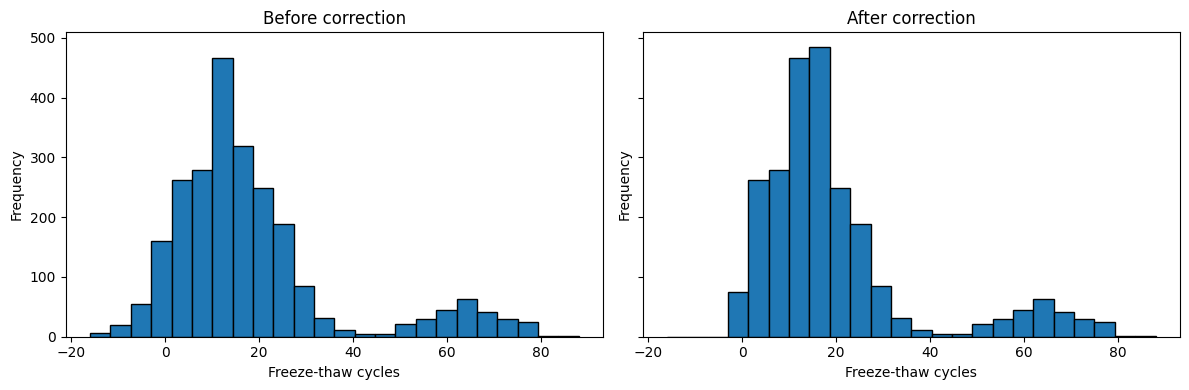

In [4]:
bins = np.linspace(before.min(), before.max(), 25)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
ax[0].hist(before, bins=bins, edgecolor='black')
ax[1].hist(after, bins=bins, edgecolor='black')
for a, title in zip(ax, ['Before correction', 'After correction']):
    a.set_title(title)
    a.set_xlabel('Freeze-thaw cycles')
    a.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

## 4. Probability distribution
Compare observed relative frequencies with Poisson and geometric distributions (geometric support starts at zero). The maximum CDF difference is descriptive, not a formal goodness-of-fit test.

Mean: 19.68125
Population variance: 305.40048177083486


,Distribution,Max CDF difference
0,Poisson,0.3830
1,Geometric (zero-based),0.1341


,count,mean,Population SD
climate_zone,,,
Cold,264,64.04,7.96
Semi-Arid,888,18.07,7.99
Temperate,1248,11.44,6.52


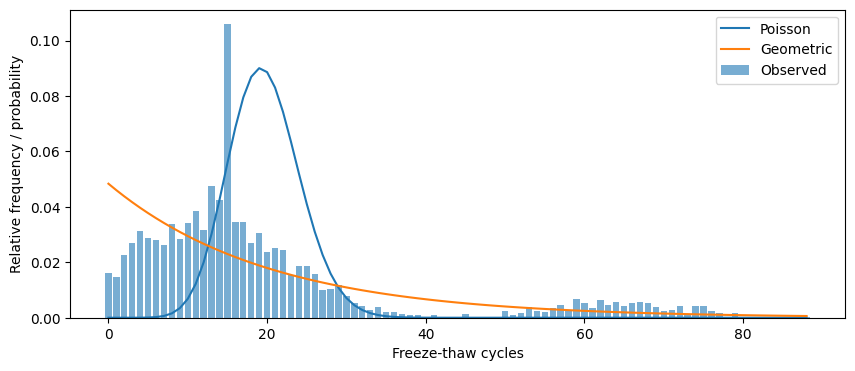

In [5]:
x = np.arange(0, int(after.max())+1)
mu = after.mean()
p_geo = 1/(mu+1)
observed = after.value_counts(normalize=True).reindex(x, fill_value=0)
empirical_cdf = observed.cumsum().to_numpy()
poisson_cdf = stats.poisson.cdf(x, mu)
geom_cdf = stats.geom.cdf(x+1, p_geo)
print('Mean:', mu)
print('Population variance:', after.var(ddof=0))
display(pd.DataFrame({'Distribution':['Poisson','Geometric (zero-based)'],
                      'Max CDF difference':[np.max(abs(empirical_cdf-poisson_cdf)), np.max(abs(empirical_cdf-geom_cdf))]}).round(4))
display(df_corrected.groupby('climate_zone')[col].agg(['count','mean',lambda s:s.std(ddof=0)]).rename(columns={'<lambda_0>':'Population SD'}).round(2))
plt.figure(figsize=(10,4))
plt.bar(x, observed, alpha=.6, label='Observed')
plt.plot(x, stats.poisson.pmf(x, mu), label='Poisson')
plt.plot(x, stats.geom.pmf(x+1, p_geo), label='Geometric')
plt.xlabel('Freeze-thaw cycles')
plt.ylabel('Relative frequency / probability')
plt.legend()
plt.show()

## 5. Normality and central limit theorem
Visual assessment using histograms and Q-Q plots. 1000 random samples of size 30, with replacement.

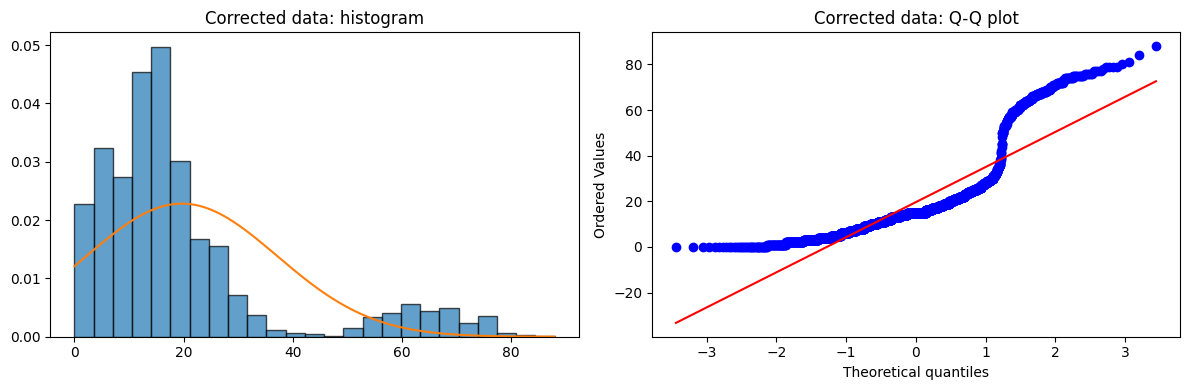

Mean of sample means: 19.79076666666667
Standard deviation of sample means: 3.2018548370797615


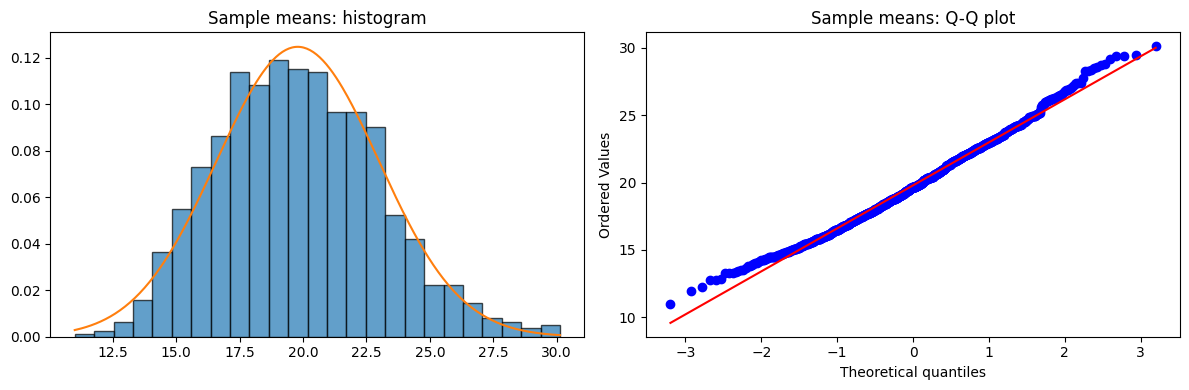

In [6]:
def normal_plots(values, title):
    values = np.asarray(values)
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    ax[0].hist(values, bins=25, density=True, edgecolor='black', alpha=.7)
    grid = np.linspace(values.min(), values.max(), 300)
    ax[0].plot(grid, stats.norm.pdf(grid, values.mean(), values.std(ddof=0)))
    ax[0].set_title(title + ': histogram')
    stats.probplot(values, dist='norm', plot=ax[1])
    ax[1].set_title(title + ': Q-Q plot')
    plt.tight_layout()
    plt.show()
normal_plots(after, 'Corrected data')
rng = np.random.default_rng(42)
samples = rng.choice(after.to_numpy(), size=(1000, 30), replace=True)
sample_means = samples.mean(axis=1)
print('Mean of sample means:', sample_means.mean())
print('Standard deviation of sample means:', sample_means.std(ddof=1))
normal_plots(sample_means, 'Sample means')

## 6. One-sided hypothesis test
H0: mean >= 20; H1: mean < 20. Use one eight-year mean per road section and the large-sample normal approximation. The three decision methods are equivalent.

In [7]:
sections = df_corrected.groupby('section_id').agg(
    freeze_thaw_cycles=(col,'mean'),
    pavement_type=('pavement_type','first'),
    climate_zone=('climate_zone','first'))
s = sections[col]
n = len(s)
mean = s.mean()
sd = s.std(ddof=1)
se = sd / np.sqrt(n)
z = (mean-20)/se
z_crit = stats.norm.ppf(alpha)
p = stats.norm.cdf(z)
upper = mean - z_crit*se
print('n:', n, 'Mean:', mean, 'Sample SD:', sd, 'SE:', se)
def decision(reject):
    return 'Reject H0' if reject else 'Fail to reject H0'
display(pd.DataFrame({'Method':['One-sided CI','Z-value','P-value'],
                      'Value':[upper,z,p], 'Critical value':[20,z_crit,alpha],
                      'Decision':[decision(upper<20),decision(z<z_crit),decision(p<alpha)]}))

n: 300 Mean: 19.68125 Sample SD: 16.11072656822219 SE: 0.9301532321003536


,Method,Value,Critical value,Decision
0,One-sided CI,21.211216,20.000000,Fail to reject H0
1,Z-value,-0.342685,-1.644854,Fail to reject H0
2,P-value,0.365918,0.050000,Fail to reject H0


## 7. Annual differences — Friedman test
H0: yearly distributions are the same. H1: at least one differs. The same road sections are measured repeatedly.

,mean,median
survey_year,,
2018,19.23,15.0
2019,19.63,14.5
2020,18.99,15.0
2021,19.13,15.0
2022,20.66,15.0
2023,20.31,15.0
2024,19.70,15.0
2025,19.80,15.0


Friedman statistic: 9.657165991902788 df: 7 P-value: 0.20884812600353173
Fail to reject H0


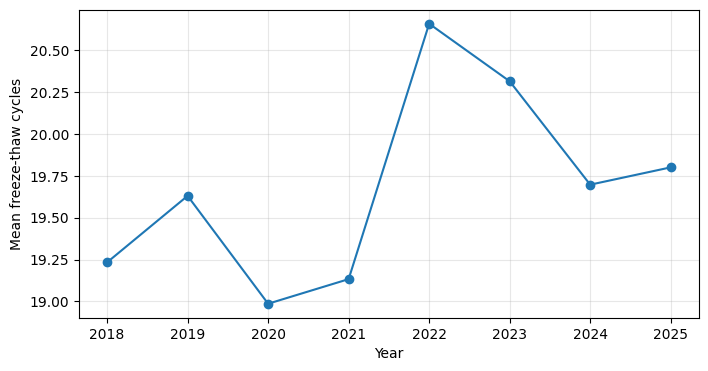

In [8]:
annual = df_corrected.groupby('survey_year')[col].agg(['mean','median'])
display(annual.round(2))
wide = df_corrected.pivot(index='section_id', columns='survey_year', values=col).dropna()
f_stat, p = stats.friedmanchisquare(*[wide[y] for y in wide.columns])
print('Friedman statistic:', f_stat, 'df:', len(wide.columns)-1, 'P-value:', p)
print(decision(p<alpha))
plt.figure(figsize=(8,4))
plt.plot(annual.index, annual['mean'], marker='o')
plt.xticks(annual.index)
plt.xlabel('Year')
plt.ylabel('Mean freeze-thaw cycles')
plt.grid(alpha=.3)
plt.show()

## 8. Pavement type — Mann–Whitney U
H0: distributions of both independent groups are the same. H1: they differ.

,count,mean,median
pavement_type,,,
Flexible,240,19.27,14.25
Rigid,60,21.34,15.44


U: 7027.5 P-value: 0.7747189746948564
Fail to reject H0


/tmp/ipykernel_681/3605236307.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([flexible,rigid], labels=['Flexible','Rigid'])


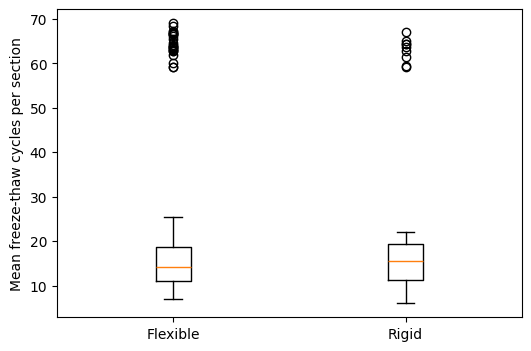

In [9]:
display(sections.groupby('pavement_type')[col].agg(['count','mean','median']).round(2))
flexible = sections.loc[sections['pavement_type']=='Flexible',col]
rigid = sections.loc[sections['pavement_type']=='Rigid',col]
u_stat, p = stats.mannwhitneyu(flexible, rigid, alternative='two-sided')
print('U:', u_stat, 'P-value:', p)
print(decision(p<alpha))
plt.figure(figsize=(6,4))
plt.boxplot([flexible,rigid], labels=['Flexible','Rigid'])
plt.ylabel('Mean freeze-thaw cycles per section')
plt.show()

## 9. Climate zone — Kruskal–Wallis
H0: distributions of all independent groups are the same. H1: at least one differs.

,count,mean,median
climate_zone,,,
Cold,33,64.04,64.00
Semi-Arid,111,18.07,17.62
Temperate,156,11.44,11.31


H: 224.13325277687161 P-value: 2.1383685281796024e-49
Reject H0


/tmp/ipykernel_681/2526083880.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([v for _,v in groups], labels=[k for k,_ in groups])


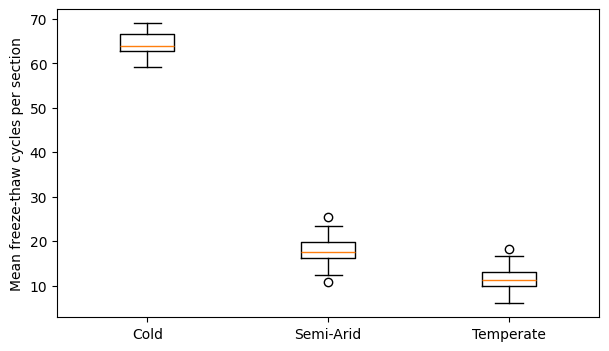

In [10]:
display(sections.groupby('climate_zone')[col].agg(['count','mean','median']).round(2))
groups = list(sections.groupby('climate_zone')[col])
h_stat, p = stats.kruskal(*[v for _,v in groups])
print('H:', h_stat, 'P-value:', p)
print(decision(p<alpha))
plt.figure(figsize=(7,4))
plt.boxplot([v for _,v in groups], labels=[k for k,_ in groups])
plt.ylabel('Mean freeze-thaw cycles per section')
plt.show()